> **Historical analysis:** this notebook retains the earlier temporal-spread response and outputs. For the current lag / plateau-duration / peak-excess metrics, start with [the results synthesis](synthetic_results_synthesis.ipynb) and [predictor validation](synthetic_predictor_validation.ipynb). Earlier `event_duration_change_pct` values here denote cumulative-volume t01–t99, not the current plateau duration.

# Slope, path-length variation and length–width association

A controlled follow-up to [the geometric predictor screen](synthetic_geometry_predictors.ipynb).
The compact reference set is **the current weighted resistance predictor $X$,
equivalent length, elongation, and dominant width fraction**. Add:

- **Existing path-length CV:** unweighted standard deviation / mean of complete domain path lengths.
- **Signed length–width association:** $A_{LW}=L_{eq}/\bar L-1$, where $L_{eq}$ is width-weighted and $\bar L$ is unweighted. Positive means longer paths receive more representative width; negative means shorter paths do. Equal lengths or equal widths give zero. This complements, rather than replaces, length CV.
- **Domain reference slope:** boundary head drop / straight centerline reference distance between the matched domain endpoints. In this synthetic design this equals the imposed reference slope, verified for every comparison. It is not an average of edge slopes, and it is not derived from whichever child path survives.

Equivalent length retains absolute length scale; elongation together with length
also retains equivalent width. Partial and island collapses use the same matched
domain definitions as the resistance analysis. Path weights are representative
path-width fractions, not measured discharge fractions.

The analysis reads saved hydrographs/metrics and geometry; no routing is rerun.
This extension admits slope explicitly, while continuing to exclude celerity,
routing coefficients, forcing duration and output-derived predictors.


**Historical supporting analysis:** this notebook retains its saved pre-selection hydraulic setup and, where applicable, earlier spread/quantile metrics. It is not an alpha=0.65 result. Use the current [results synthesis](synthetic_results_synthesis.ipynb) and [predictor validation](synthetic_predictor_validation.ipynb) for the selected setup.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'synthetic_experiments').is_dir())
OUT=ROOT/'synthetic_experiments/outputs/full_grid_island/factor_analysis/geometry_predictors/slope_path_arrangement'
meta=json.loads((OUT/'provenance.json').read_text())
data=pd.read_parquet(OUT/'features.parquet')
cv=pd.read_csv(OUT/'development_scores.csv');test=pd.read_csv(OUT/'held_out_scores.csv')
RESPONSE={'lag_shift_pct':'Peak-lag change','temporal_spread_change_pct':'Temporal-spread change','peak_excess_change_pct':'Peak-excess change'}
assert len(data)==15309
assert np.allclose(data.domain_reference_slope,data.reference_slope,rtol=1e-10)
assert data.groupby('geometry_group').split.nunique().max()==1
assert np.isfinite(data[list(RESPONSE)+['signed_length_width_association','domain_reference_slope']]).all().all()
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
print(f'{len(data):,} comparisons; {data.geometry_group.nunique():,} geometry groups; {meta["unique_products"]} scalar products.')
display(data.groupby('child_state').signed_length_width_association.agg(['min','median','max']).round(3))


15,309 comparisons; 4,293 geometry groups; 230 scalar products.


,min,median,max
child_state,,,
crossover/downstream_only,-0.034,0.0,0.065
crossover/full,-0.034,0.0,0.065
crossover/upstream_only,-0.034,0.0,0.065
nested/full,-0.035,0.0,0.058
nested/inner_only,-0.120,0.0,0.120
nested/main_island_only,-0.035,0.0,0.058
simple/full,0.000,0.0,0.160


## Same validation, controlled additions

Use the same geometry-group development/holdout partition as the preceding
product search. All slope versions of a geometry stay together. Four-fold
validation within development data supports candidate selection; held-out scores
allow a matched comparison with the previous analysis. Because this is an
exploratory continuation of an already examined dataset, the holdout is **not a
new untouched confirmatory dataset**.

Each response has one fitted function across all collapse types, without type as
an input. The multivariable model is unchanged: 80 boosted-tree iterations,
maximum seven leaves, minimum leaf size 20 and L2 regularization 1. No retuning.
Report the mean of within-type R² across the seven types, not pooled R². Negative
values indicate worse performance than the within-type mean benchmark. Errors
are in percentage points.


response,Peak-lag change,Temporal-spread change,Peak-excess change
model,,,
Current X alone,0.574,-0.001,-0.002
Compact reference,0.763,0.484,0.531
+ length CV,0.786,0.495,0.533
+ signed association,0.800,0.514,0.552
+ CV and association,0.808,0.511,0.563
+ slope,0.791,0.632,0.684
+ slope and CV,0.819,0.632,0.692
+ slope and association,0.838,0.658,0.720
"+ slope, CV and association",0.854,0.656,0.735


response,Peak-lag change,Temporal-spread change,Peak-excess change
model,,,
Current X alone,4.18,10.45,9.35
Compact reference,2.88,6.98,6.20
+ length CV,2.65,6.94,6.19
+ signed association,2.57,6.87,6.06
+ CV and association,2.42,6.90,6.02
+ slope,2.81,5.02,4.56
+ slope and CV,2.53,5.06,4.49
+ slope and association,2.41,4.96,4.23
"+ slope, CV and association",2.21,4.96,4.13


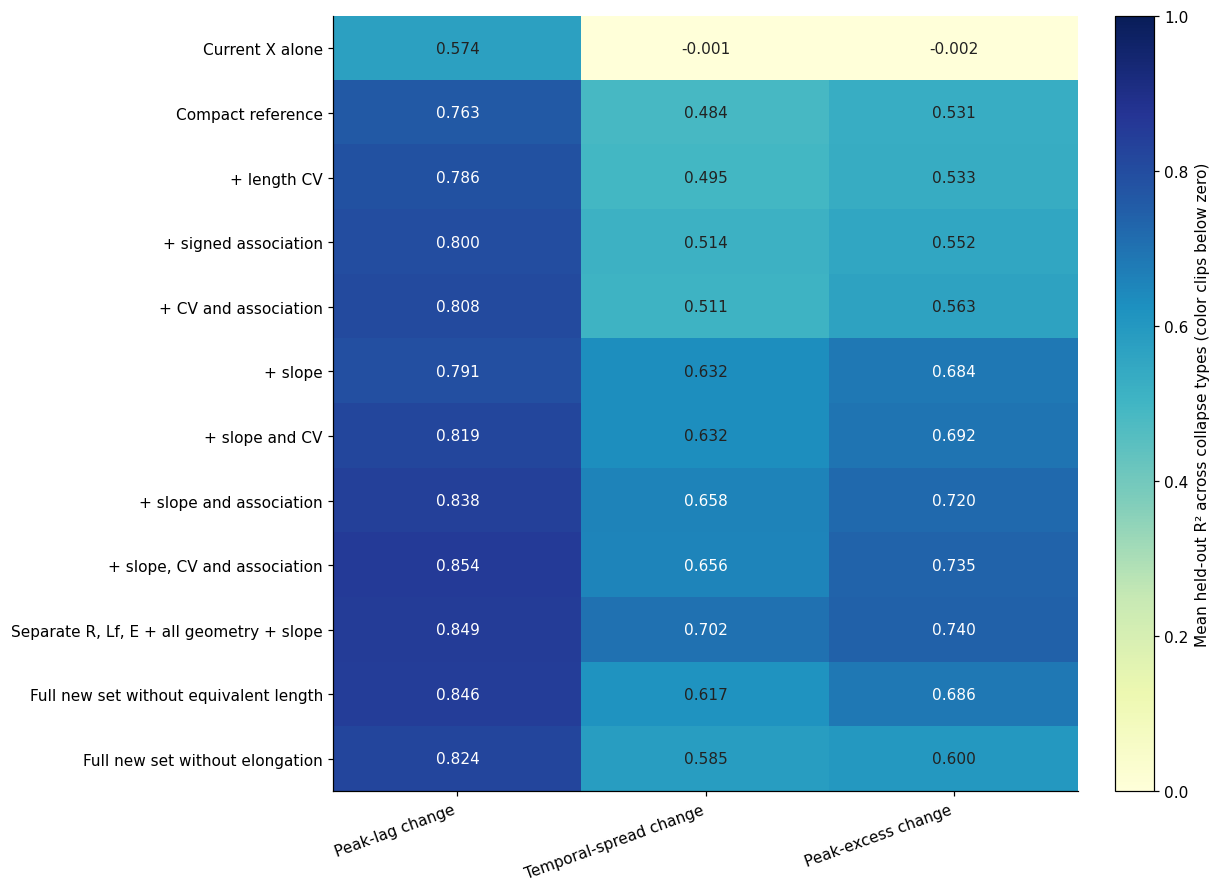

response,Peak-lag change,Temporal-spread change,Peak-excess change
Slope added to compact,0.028,0.148,0.153
CV + association added to compact,0.044,0.026,0.033
CV + association added after slope,0.063,0.023,0.052


In [2]:
LABELS={'current_product':'Current X alone','compact':'Compact reference',
 'compact_plus_CV':'+ length CV','compact_plus_association':'+ signed association',
 'compact_plus_CV_association':'+ CV and association','compact_plus_slope':'+ slope',
 'compact_plus_slope_CV':'+ slope and CV','compact_plus_slope_association':'+ slope and association',
 'compact_plus_all':'+ slope, CV and association','separate_components_plus_all':'Separate R, Lf, E + all geometry + slope',
 'compact_without_length_plus_all':'Full new set without equivalent length',
 'compact_without_elongation_plus_all':'Full new set without elongation'}
means=test.groupby(['model','response']).r2.mean().unstack().reindex(index=LABELS,columns=RESPONSE)
errors=test.groupby(['model','response']).mae_pp.mean().unstack().reindex(index=LABELS,columns=RESPONSE)
display(means.rename(index=LABELS,columns=RESPONSE).round(3))
display(errors.rename(index=LABELS,columns=RESPONSE).round(2))
fig,ax=plt.subplots(figsize=(11,8),constrained_layout=True)
im=ax.imshow(means,cmap='YlGnBu',vmin=0,vmax=1,aspect='auto')
ax.set_xticks(range(3),RESPONSE.values(),rotation=20,ha='right');ax.set_yticks(range(len(LABELS)),LABELS.values())
for (i,j),v in np.ndenumerate(means.to_numpy()):ax.text(j,i,f'{v:.3f}',ha='center',va='center',color='white' if v>.65 else '#222')
fig.colorbar(im,ax=ax,label='Mean held-out R² across collapse types (color clips below zero)')
fig.savefig(OUT/'staged_predictor_comparison.png',dpi=180);display(fig);plt.close(fig)
# Paired gains distinguish the contribution from slope and the new geometry.
gains=pd.DataFrame({
 'Slope added to compact':means.loc['compact_plus_slope']-means.loc['compact'],
 'CV + association added to compact':means.loc['compact_plus_CV_association']-means.loc['compact'],
 'CV + association added after slope':means.loc['compact_plus_all']-means.loc['compact_plus_slope']}).T
display(gains.rename(columns=RESPONSE).round(3));gains.to_csv(OUT/'paired_r2_gains.csv')


## Where does the full new set still miss?

These are predictions on held-out geometries for the compact reference plus
slope, CV and signed association. The diagonal is exact prediction. Points are
colored by imposed slope to expose residual structure. No output-derived
quantity is used to construct the predictor inputs.


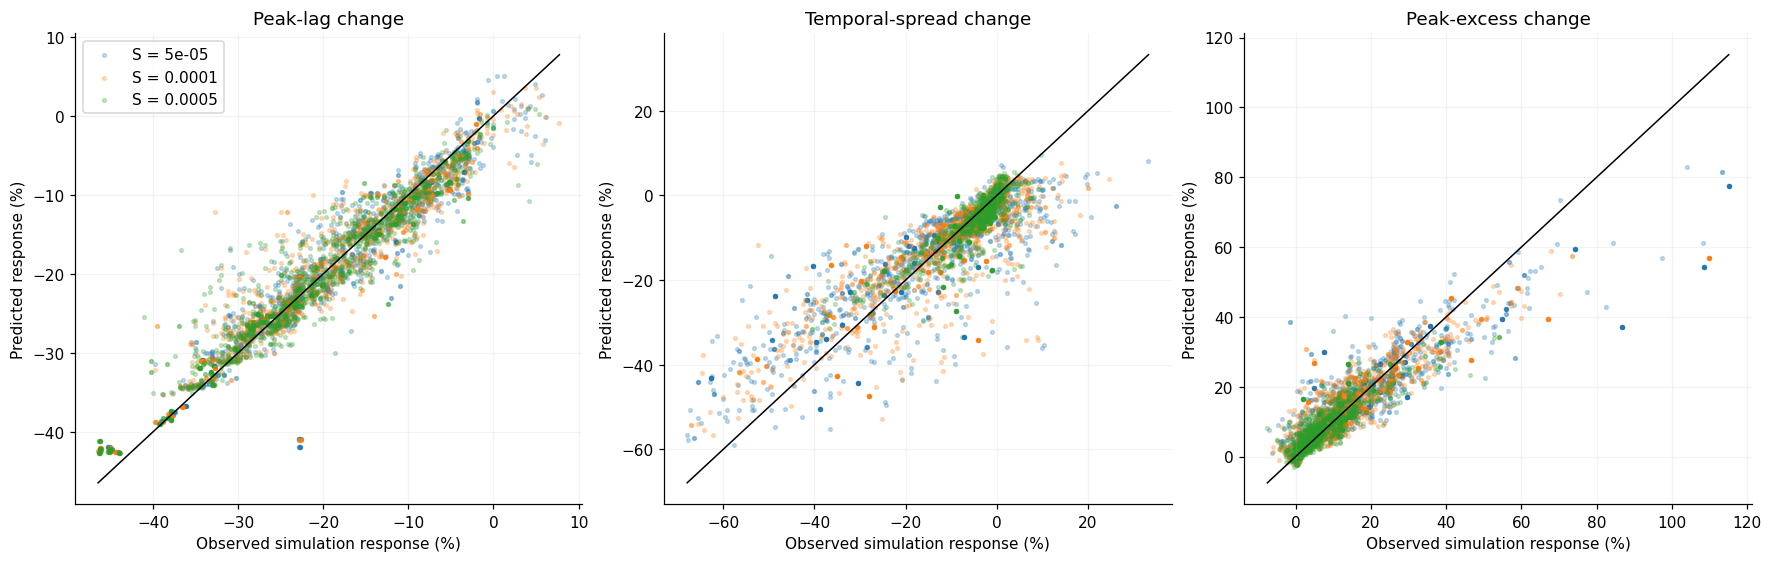

In [3]:
pred=pd.read_parquet(OUT/'held_out_predictions.parquet')
pred=pred[pred.model.eq('compact_plus_all')].merge(
 data[['configuration_id','child_state','reference_slope']],
 left_on=['configuration_id','state'],right_on=['configuration_id','child_state'],validate='many_to_one')
fig,axes=plt.subplots(1,3,figsize=(16,5),constrained_layout=True)
for ax,(response,title) in zip(axes,RESPONSE.items()):
 part=pred[pred.response.eq(response)]
 for slope,g in part.groupby('reference_slope'):ax.scatter(g.observed,g.predicted,s=6,alpha=.25,label=f'S = {slope:g}',rasterized=True)
 lo=min(part.observed.min(),part.predicted.min());hi=max(part.observed.max(),part.predicted.max())
 ax.plot([lo,hi],[lo,hi],color='black',lw=1);ax.set(title=title,xlabel='Observed simulation response (%)',ylabel='Predicted response (%)');ax.grid(alpha=.15)
axes[0].legend();fig.savefig(OUT/'held_out_response_predictions.png',dpi=180);display(fig);plt.close(fig)


## Multiplicative single-axis candidates

Search products of one, two or three distinct quantities from the compact
geometry, CV, signed association, slope, and resistance components (including
raw Lambda and the current composite X). Equivalent products are deduplicated.
A shared product maximizes mean development R² across responses/types; a balanced
shared candidate maximizes the weakest response's mean R². Separate products
maximize each response's development score.

Every scalar is fitted using the same small quadratic spline with training-only
knots and fixed regularization; this is a readable x-axis, not an assumed linear
law. The same curve is used across collapse types for each response. Products
containing CV or association collapse to zero when that factor is zero, which
can discard useful distinctions. No reciprocal or fitted-power search is included.


,Selection,Product
0,shared,resistance_log * length_fraction * parent_domi...
1,balanced_shared,Lambda_matched * parent_elongation * parent_do...
2,lag_shift_pct,resistance_predictor * parent_dominant_width_f...
3,temporal_spread_change_pct,length_fraction * parent_elongation * parent_d...
4,peak_excess_change_pct,parent_elongation


response,Peak-lag change,Temporal-spread change,Peak-excess change
selection,,,
balanced_shared,-0.093,0.034,0.013
lag_shift_pct,0.478,-0.154,-0.074
peak_excess_change_pct,-0.472,0.025,0.124
shared,0.458,-0.129,-0.066
temporal_spread_change_pct,-0.465,0.143,0.188


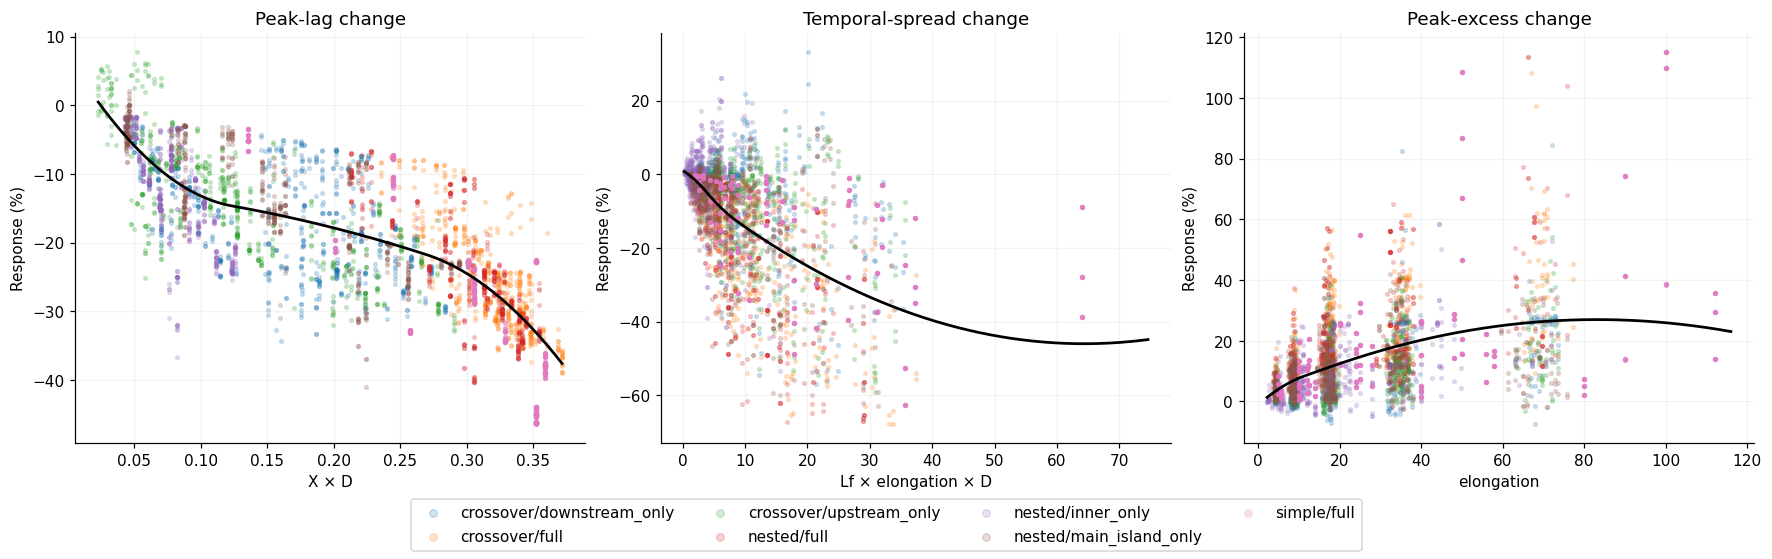

In [4]:
scalar=pd.read_csv(OUT/'product_held_out_scores.csv')
display(pd.DataFrame([{'Selection':k,'Product':v} for k,v in meta['selected_products'].items()]))
display(scalar.groupby(['selection','response']).r2.mean().unstack().reindex(columns=RESPONSE).rename(columns=RESPONSE).round(3))
p=pd.read_parquet(OUT/'product_held_out_predictions.parquet');curves=pd.read_csv(OUT/'product_curves.csv')
SYMBOLS={'resistance_log':'R','length_fraction':'Lf','width_fraction':'E','Lambda_matched':'Λ','resistance_predictor':'X',
 'parent_equivalent_length':'L','parent_elongation':'elongation','parent_dominant_width_fraction':'D',
 'parent_path_length_cv':'CV','signed_length_width_association':'A_LW','domain_reference_slope':'S'}
fig,axes=plt.subplots(1,3,figsize=(16,5),constrained_layout=True)
for ax,(response,title) in zip(axes,RESPONSE.items()):
 part=p[(p.selection==response)&(p.response==response)]
 for state,g in part.groupby('state'):ax.scatter(g.x,g.observed,s=6,alpha=.2,label=state,rasterized=True)
 line=curves[(curves.selection==response)&(curves.response==response)]
 ax.plot(line.x,line.predicted,color='black',lw=1.8)
 label=' × '.join(SYMBOLS[c] for c in meta['selected_products'][response].split(' * '))
 ax.set(title=title,xlabel=label,ylabel='Response (%)');ax.grid(alpha=.15)
handles,labels=axes[0].get_legend_handles_labels();fig.legend(handles,labels,loc='outside lower center',ncol=4,markerscale=2)
fig.savefig(OUT/'best_product_axes.png',dpi=180);display(fig);plt.close(fig)


## Preliminary interpretation

The compact reference achieves held-out mean R² of **0.763 / 0.484 / 0.531**
for lag / spread / peak excess. Adding CV and signed association gives
**0.808 / 0.511 / 0.563**. Adding slope alone gives **0.791 / 0.632 / 0.684**.
All three additions give **0.854 / 0.656 / 0.735**.

Thus slope supplies the larger improvement for both shape responses in this
controlled comparison. The signed association is more helpful than length CV
alone; once association and slope are included, CV gives a further small gain in
lag and peak excess but no gain in spread on this holdout. The descriptors are
not independent, so these are conditional model comparisons rather than isolated
physical contributions.

Keeping R, length fraction and exposure as separate inputs with the new geometry
and slope gives **0.849 / 0.702 / 0.740**. Removing equivalent length or elongation
reduces shape performance: absolute scale and width information remain useful.
The association therefore complements size; it does not replace it.

The scalar-product search still yields weak shape prediction (approximately
0.14 for spread and 0.12 for peak excess for the selected response-specific axes).
The best products in this restricted family omit slope, despite its clear benefit
as a separate input. That is evidence about the inadequacy of simple multiplication
here, not evidence that slope is unimportant. The scalar calibration model differs
from the multivariable model, so the difference is not attributable solely to the
number of inputs.

These are exploratory results on the synthetic grid and the reused validation
partition. They support retaining reference slope and the signed path association
for further interpretation, but do not establish a universal equation or predictive
performance on real networks.
